In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

print("TensorFlow version:", tf.__version__)
print("Setup completed successfully!")

TensorFlow version: 2.21.0
Setup completed successfully!


In [2]:
# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)
print("First 10 labels:", y_train[:10])

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)
First 10 labels: [5 0 4 1 9 2 1 3 1 4]


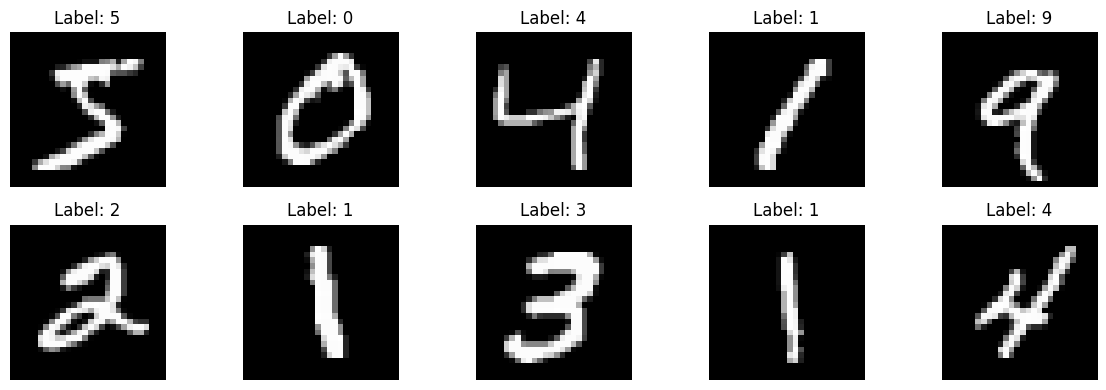

In [3]:
# Display first 10 handwritten digits
plt.figure(figsize=(12, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [4]:
# Normalize pixel values
x_train = x_train / 255.0
x_test = x_test / 255.0

# Add channel dimension for CNN
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

Training data shape: (60000, 28, 28, 1)
Testing data shape: (10000, 28, 28, 1)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [5]:
# Create CNN model
model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),

    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1
)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 47s 105ms/step - accuracy: 0.9037 - loss: 0.3153 - val_accuracy: 0.9793 - val_loss: 0.0705
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 43s 103ms/step - accuracy: 0.9698 - loss: 0.0999 - val_accuracy: 0.9855 - val_loss: 0.0505
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 82s 103ms/step - accuracy: 0.9773 - loss: 0.0765 - val_accuracy: 0.9887 - val_loss: 0.0424
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 83s 106ms/step - accuracy: 0.9819 - loss: 0.0600 - val_accuracy: 0.9867 - val_loss: 0.0418
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 80s 102ms/step - accuracy: 0.9835 - loss: 0.0513 - val_accuracy: 0.9872 - val_loss: 0.0441


In [7]:
# Evaluate the model on test data
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

Test Loss: 0.0381
Test Accuracy: 98.76 %


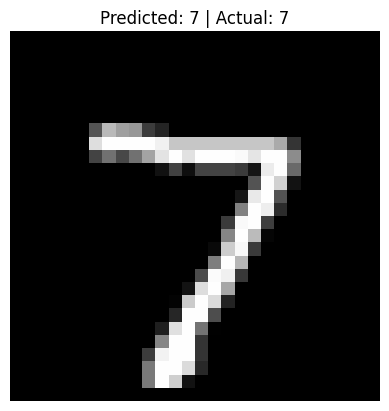

Predicted digit: 7
Actual digit: 7


In [8]:
# Predict a test image
index = 0

prediction = model.predict(x_test[index:index+1], verbose=0)
predicted_digit = np.argmax(prediction)

plt.imshow(x_test[index].reshape(28, 28), cmap="gray")
plt.title(f"Predicted: {predicted_digit} | Actual: {y_test[index]}")
plt.axis("off")
plt.show()

print("Predicted digit:", predicted_digit)
print("Actual digit:", y_test[index])

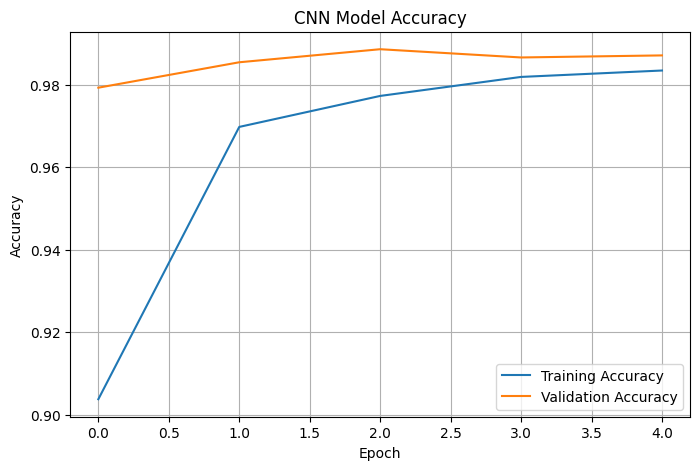

In [9]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('CNN Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

In [10]:
# Save the trained CNN model
model.save("CodeAlpha_HandwrittenCharacterRecognition.keras")

print("Model saved successfully!")

Model saved successfully!


In [11]:
from google.colab import files

files.download("CodeAlpha_HandwrittenCharacterRecognition.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>